# Ryan Ravikumar - 9/10/2026 - Analytics for FinSight

## Data Cleaning Process

In [6]:
%pip install pandas numpy scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [7]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [17]:
import pandas as pd
import numpy as np
from scipy import stats

raw = pd.read_excel("initial_data/FinSight_Dataset.xlsx")
df = raw.copy()
print(df.shape)
df.head()

(508, 44)


,Customer_ID,Full_Name,NIC_Number,Gender,Date_of_Birth,Age,District,Province,Urban_Rural,Customer_Segment,...,PEP_Flag,Has_Fixed_Deposit,FD_Amount,Has_Insurance,Has_Mobile_Wallet,Number_of_Products,Acquisition_Channel,Referral_Source,Last_Campaign_Response,Promo_Code_Used
0,FSL-0001,Mark Johnson,808614657V,Female,1980-12-26,43,Kandy,Central,Suburban,Regular,...,No,No,NaN,No,Yes,2,Referral,Friend,Responded,Yes
1,FSL-0002,Deborah Phillips,718478527V,Female,1971-12-13,52,Badulla,Uva,Urban,Starter,...,No,No,NaN,No,Yes,2,Referral,Family,Ignored,No
2,FSL-0003,Charles Phillips,933515010V,Male,1993-12-17,30,Kandy,Central,Suburban,Regular,...,No,Yes,1166599.45,No,No,3,Agent,Colleague,Responded,No
3,FSL-0004,Rachel Hall,720422796V,Male,1972-02-11,51,Kandy,Central,Suburban,Regular,...,No,Yes,1051113.61,Yes,No,4,Referral,NaN,Ignored,Yes
4,FSL-0005,Sharon Bell,940729689V,Male,1994-03-13,29,Colombo,Western,Suburban,Regular,...,No,No,NaN,No,Yes,3,Referral,NaN,Unsubscribed,No


Data inspection

In [16]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Customer_ID                508 non-null    str           
 1   Full_Name                  500 non-null    str           
 2   NIC_Number                 508 non-null    str           
 3   Gender                     508 non-null    str           
 4   Date_of_Birth              508 non-null    datetime64[us]
 5   Age                        508 non-null    int64         
 6   District                   503 non-null    str           
 7   Province                   508 non-null    str           
 8   Urban_Rural                508 non-null    str           
 9   Customer_Segment           503 non-null    str           
 10  Account_Open_Date          508 non-null    datetime64[us]
 11  Customer_Tenure_Years      508 non-null    float64       
 12  Savings_Balance    

,count,mean,min,25%,50%,75%,max,std
Date_of_Birth,508,1986-11-01 10:37:47.716535,1890-03-11 00:00:00,1978-06-15 18:00:00,1987-01-15 12:00:00,1995-06-16 00:00:00,2020-05-01 00:00:00,NaN
Age,508.0,37.005906,4.0,28.0,36.5,45.0,150.0,12.132973
Account_Open_Date,508,2019-07-29 12:42:31.181102,2015-01-14 00:00:00,2017-02-04 18:00:00,2019-09-05 00:00:00,2021-10-21 18:00:00,2026-06-01 00:00:00,NaN
Customer_Tenure_Years,508.0,4.450394,0.0,2.2,4.3,6.9,9.0,2.635717
Savings_Balance,502.0,2751255.695717,-88000.0,120697.155,442763.82,729013.3525,999999999.0,44611330.086692
Monthly_Deposit_Avg,502.0,37871.756454,194.79,5607.16,17694.735,39642.0225,347140.12,57934.118045
Monthly_Withdrawal_Avg,508.0,59007.534528,100.99,3230.255,9684.8,22889.24,9999999.0,592686.17979
Net_Monthly_Flow,508.0,15896.003681,30.87,1850.815,5851.795,16963.655,196240.99,26785.955644
Loan_Amount,217.0,1427319.142258,54308.53,708817.38,1421377.63,2114078.24,2998363.15,847290.637522
Loan_Tenure_Months,218.0,34.12844,12.0,12.0,36.0,48.0,60.0,17.48474


**Concerns**
Minimum and maximum of "Age" indicates ages of 4 and 150, needs further investigating.

In [18]:
df.loc[df["Age"]==4].T

,33
Customer_ID,FSL-0034
Full_Name,Susan Jones
NIC_Number,961124538V
Gender,Male
Date_of_Birth,2020-05-01 00:00:00
Age,4
District,Galle
Province,Southern
Urban_Rural,Urban
Customer_Segment,Premium


While there is no explicit rule to handle the minimum "Age" value (4), the following evidence suggests handling is necessary:
1. The "Mobile_App_User" is set to "Yes", which isn't possible given age.
2. The "Account_Open_Date" value indicates that the user was a year old upon account creation.
3. The "NIC_Number" contains a value, this is not possible for a four year old to obtain.

In [24]:
df.loc[(df["Age"]-4).abs().sort_values().index[:5]].T

,33,319,467,77,273
Customer_ID,FSL-0034,FSL-0320,FSL-0468,FSL-0078,FSL-0274
Full_Name,Susan Jones,Samantha Moore,Rachel Allen,Lisa Thompson,Amanda Anderson
NIC_Number,961124538V,027878908V,026797630V,020317932V,023164687V
Gender,Male,Female,Female,Male,Male
Date_of_Birth,2020-05-01 00:00:00,2002-10-14 00:00:00,2002-06-28 00:00:00,2002-01-31 00:00:00,2002-11-12 00:00:00
Age,4,21,21,21,21
District,Galle,Galle,Colombo,Kurunegala,Colombo
Province,Southern,Southern,Western,North Western,Western
Urban_Rural,Urban,Urban,Rural,Urban,Rural
Customer_Segment,Premium,Regular,Regular,Starter,Regular


4. The above data indicates that the closest value to the minimum of "Age" is 21, which makes it more likely to be a typo.

In [25]:
df.loc[df["Age"]==150].T

,270
Customer_ID,FSL-0271
Full_Name,Gary Taylor
NIC_Number,755708899V
Gender,Female
Date_of_Birth,1975-03-11 00:00:00
Age,150
District,Badulla
Province,Uva
Urban_Rural,Urban
Customer_Segment,Regular


An investigation of the maximum reveals the following:
1. A contradication between "Age" (150) and the "Date_of_Birth" (1975-03-11).

In [28]:
df.isna().sum()

Customer_ID                    0
Full_Name                      8
NIC_Number                     0
Gender                         0
Date_of_Birth                  0
Age                            0
District                       5
Province                       0
Urban_Rural                    0
Customer_Segment               5
Account_Open_Date              0
Customer_Tenure_Years          0
Savings_Balance                6
Monthly_Deposit_Avg            6
Monthly_Withdrawal_Avg         0
Net_Monthly_Flow               0
Account_Status                 0
Interest_Rate_Tier             0
Has_Loan                       5
Loan_Type                    290
Loan_Amount                  291
Loan_Tenure_Months           290
Monthly_Repayment_Amount     290
Loan_Repayment_Status        288
Loan_Start_Date              288
Outstanding_Loan_Balance     289
Mobile_App_User                0
Last_Login_Date              169
Monthly_Transaction_Count      0
Preferred_Channel              0
Push_Notif

Concerns over missing "FD_Amount", can be addressed if "Has_Fixed_Deposit" where the sumation of value "No" aligns with missing values in "FD_Amount."

In [29]:
df["Has_Fixed_Deposit"].value_counts(dropna=False)

Has_Fixed_Deposit
No     358
Yes    150
Name: count, dtype: int64

This confirms previous assumption where both "No" and missing values in "FD_Amount" is 358.

The "Has_loan" and "Loan_Type" columns also need to be investigated. 

In [37]:
pd.crosstab(df["Has_Loan"].fillna("Missing"), df["Loan_Type"].isna(), rownames=["Has Loan"], 
            colnames=["Loan Type Missing"], margins=True)

Loan Type Missing,False,True,All
Has Loan,,,
Missing,1,4,5
No,1,284,285
Yes,216,2,218
All,218,290,508


The results point to the following concerns:
1. The 5 customers that have missing "Has_Loan" values, 4 have missing "Loan_Type" values but 1 has a "Loan_type" value recorded.
2. One customer that was marked as "No" contains a "Loan_Type."
3. 2 customers that marked "Yes" contain missing "Loan_Type."

In [38]:
cols_to_check=["Gender", "District", "Account_Status", "Customer_Segment", "Has_Loan"]

for col in cols_to_check:
    print(df[col].value_counts(dropna=False), "\n")

print("Duplicated (Identical): ", df.duplicated().sum())
print("Duplicated primay key (Customer_ID): ", df["Customer_ID"].duplicated().sum())
df.tail(10)

Gender
Female    261
Male      241
M           1
male        1
FEMALE      1
F           1
MALE        1
f           1
Name: count, dtype: int64 

District
Jaffna         58
Kurunegala     56
Ratnapura      56
Gampaha        54
Badulla        50
Trincomalee    50
Colombo        49
Kandy          46
Matara         46
Galle          34
NaN             5
Columbo         1
Kanady          1
Gale            1
Jafna           1
Name: count, dtype: int64 

Account_Status
Active       382
Inactive      80
Suspended     42
active         1
INACTIVE       1
suspended      1
Active         1
Name: count, dtype: int64 

Customer_Segment
Regular    319
Starter     93
Premium     91
NaN          5
Name: count, dtype: int64 

Has_Loan
No     285
Yes    218
NaN      5
Name: count, dtype: int64 

Duplicated (Identical):  3
Duplicated primay key (Customer_ID):  8


,Customer_ID,Full_Name,NIC_Number,Gender,Date_of_Birth,Age,District,Province,Urban_Rural,Customer_Segment,...,PEP_Flag,Has_Fixed_Deposit,FD_Amount,Has_Insurance,Has_Mobile_Wallet,Number_of_Products,Acquisition_Channel,Referral_Source,Last_Campaign_Response,Promo_Code_Used
498,FSL-0499,Michael Johnson,850037799V,Male,1985-01-03,39,Gampaha,Western,Suburban,Starter,...,No,No,NaN,Yes,Yes,3,Referral,NaN,Responded,Yes
499,FSL-0500,Janet Parker,748239834V,Female,1974-11-19,49,Matara,Southern,Urban,Regular,...,No,Yes,1087392.46,No,No,3,Referral,NaN,Responded,No
500,FSL-0011,Joshua Mitchell,862063426V,Male,1986-07-25,37,Kurunegala,North Western,Urban,Regular,...,No,No,NaN,Yes,No,2,Referral,NaN,Ignored,No
501,FSL-0046,Nicole Morris,012378685V,Male,2001-08-25,22,Ratnapura,Sabaragamuwa,Suburban,Starter,...,No,Yes,1819779.08,No,Yes,3,Branch,NaN,Responded,No
502,FSL-0089,Catherine Mitchell,821642369V,Male,1982-06-13,41,Matara,Southern,Urban,Starter,...,No,Yes,1365551.20,No,Yes,3,Digital,NaN,Responded,Yes
503,FSL-0131,Ryan Torres,992664913V,Male,1999-09-23,24,Trincomalee,Eastern,Suburban,Regular,...,No,Yes,492870.74,No,Yes,3,Agent,NaN,Unsubscribed,Yes
504,FSL-0201,Nancy Johnson,821599078V,Male,1982-06-08,41,Gampaha,Western,Suburban,Regular,...,No,No,NaN,Yes,Yes,3,Referral,Friend,Responded,No
505,FSL-0281,Linda Scott,916433090V,Female,1991-05-23,32,Matara,Southern,Urban,Regular,...,No,Yes,912753.66,No,No,2,Branch,Colleague,Ignored,Yes
506,FSL-0351,Charles Morgan,717648100V,Female,1971-09-21,52,Gampaha,Western,Rural,Regular,...,No,No,NaN,No,Yes,2,Branch,NaN,Unsubscribed,No
507,FSL-0421,Nicole Roberts,827457336V,Female,1982-09-02,41,Ratnapura,Sabaragamuwa,Rural,Regular,...,No,Yes,404601.63,No,Yes,3,Referral,Family,Responded,No


The results point to the following concerns:
1. There seems to be no standardized format for "Gender", values include "Female", "Male", "M", "male", "FEMALE", "F", "MALE", "f."
2. The "District" column contains typos "Columbo", "Kanady", "Gale", "Jafna", these values have lead to duplicates in the number of categories.
3. The "Customer_ID" with is assumed to be the primary identifier is duplicated over 8 times, while 3 entire rows seem identical.
4. Same standardization issue occurs with "Account_Status" where values include "Active", "Inactive", "Suspended", "active", "INACTIVE", "suspended", "Active."
5. "District", "Customer_Segment", "Has_Loan" ("Has_Loan" was identified previously) has 5 missing values.

In [41]:
missing_val_cols=["Customer_ID", "District", "Customer_Segment", "Has_Loan"]

print(df.loc[df[["District", "Customer_Segment", "Has_Loan"]].isna().any(axis=1), missing_val_cols])

    Customer_ID     District Customer_Segment Has_Loan
28     FSL-0029      Colombo              NaN       No
50     FSL-0051          NaN          Regular       No
85     FSL-0086    Ratnapura          Regular      NaN
92     FSL-0093   Kurunegala              NaN       No
120    FSL-0121          NaN          Regular       No
165    FSL-0166      Colombo          Regular      NaN
168    FSL-0169  Trincomalee              NaN       No
225    FSL-0226      Colombo          Premium      NaN
230    FSL-0231          NaN          Regular      Yes
275    FSL-0276       Matara              NaN      Yes
355    FSL-0356      Colombo          Starter      NaN
370    FSL-0371          NaN          Regular      Yes
400    FSL-0401      Badulla              NaN      Yes
450    FSL-0451          NaN          Regular      Yes
475    FSL-0476      Badulla          Regular      NaN


### How Old is the Data?

To test the validity of the date values in the data it is important for us to understand when the data was captured. This is not explicity mentioned and therefore requires evidence to suggest a close enough date.

The first method we can use would be to **current_date = Account_Open_Date + Customer_Tenure_Years**

In [42]:
implied = df["Account_Open_Date"] + pd.to_timedelta(df["Customer_Tenure_Years"] * 365.25, unit="D")

print("Middle (median) implied date: ", implied.median().date())
print("Middle 90% of rows: ", implied.quantile(0.05).date(), "to", implied.quantile(0.95).date())

Middle (median) implied date:  2023-12-31
Middle 90% of rows:  2023-12-16 to 2024-01-18


In [43]:
def tenure_matches(day):
    tenure = ((day - df["Account_Open_Date"]).dt.days / 365.25).round(1)
    return (tenure == df["Customer_Tenure_Years"]).sum()
    
days = pd.date_range("2023-10-01", "2024-03-31")
scores = pd.Series({day.date(): tenure_matches(day) for day in days})
print(scores.sort_values(ascending=False).head(5))

for col in ["Loan_Start_Date", "KYC_Last_Updated", "Last_Login_Date"]:
    print(col, df[col].dropna().sort_values().tail(4).dt.date.tolist())

2024-01-03    494
2024-01-02    494
2024-01-01    489
2024-01-04    480
2023-12-31    478
dtype: int64
Loan_Start_Date [datetime.date(2023, 12, 15), datetime.date(2023, 12, 17), datetime.date(2023, 12, 21), datetime.date(2023, 12, 31)]
KYC_Last_Updated [datetime.date(2023, 12, 30), datetime.date(2024, 1, 1), datetime.date(2024, 1, 1), datetime.date(2024, 1, 1)]
Last_Login_Date [datetime.date(2024, 1, 1), datetime.date(2025, 8, 20), datetime.date(2026, 3, 15), datetime.date(2027, 1, 1)]


According to the above results it is best to assume the date to be **"2024-01-03"**

### Date Investigations

In [49]:
current_date=pd.Timestamp("2024-01-03") #Assumed informed current date based on previous evidence

print("Latest KYC update: ", df["KYC_Last_Updated"].max().date()) #Get latest KYC date
print("Accounts opened after assumed current date: ", (df["Account_Open_Date"]>current_date).sum())
print("Last logins after the current date: ", (df["Last_Login_Date"]>current_date).sum())
print("Loan starting before an account opens: ", (df["Loan_Start_Date"]<df["Account_Open_Date"]).sum())


Latest KYC update:  2024-01-01
Accounts opened after assumed current date:  2
Last logins after the current date:  3
Loan starting before an account opens:  4


### Money Columns

In [45]:
print("Negative savings balances: ", (df["Savings_Balance"]<0).sum()) #Negative balances
print("Balances of more than 100 million: ", (df["Savings_Balance"]>=100000000).sum()) #Extremely high balances
print("Widthdrawals of more than 1 million given a month: ", (df["Monthly_Withdrawal_Avg"]>=1000000).sum()) #High widthdrawal, not conclusive to be addressed.

Negative savings balances:  4
Balances of more than 100 million:  1
Widthdrawals of more than 1 million given a month:  2


In [46]:

# Inspect negative savings balances
display(
    df.loc[
        df["Savings_Balance"] < 0,
        ["Customer_ID", "Savings_Balance"]
    ]
)

# Inspect extremely high savings balances
display(
    df.loc[
        df["Savings_Balance"] >= 100000000,
        ["Customer_ID", "Savings_Balance"]
    ]
)

# Inspect unusually high monthly withdrawals
display(
    df.loc[
        df["Monthly_Withdrawal_Avg"] >= 1000000,
        ["Customer_ID", "Monthly_Withdrawal_Avg"]
    ]
)

,Customer_ID,Savings_Balance
22,FSL-0023,-45000.0
99,FSL-0100,-12500.0
175,FSL-0176,-88000.0
320,FSL-0321,-5000.0


,Customer_ID,Savings_Balance
55,FSL-0056,999999999.0


,Customer_ID,Monthly_Withdrawal_Avg
125,FSL-0126,9999999.0
295,FSL-0296,8888888.0


The negative balances isn't evidence enough to be replaced since buisness rules are unavilable and non of the negative values appear extreme.

In [47]:

flagged_ids = [
    "FSL-0023",
    "FSL-0100",
    "FSL-0176",
    "FSL-0321",
    "FSL-0056",
    "FSL-0126",
    "FSL-0296"
]

columns_to_check = [
    "Customer_ID",
    "Age",
    "District",
    "Customer_Segment",
    "Savings_Balance",
    "Monthly_Deposit_Avg",
    "Monthly_Withdrawal_Avg",
    "Net_Monthly_Flow",
    "Has_Loan",
    "Account_Status"
]

display(
    df.loc[
        df["Customer_ID"].isin(flagged_ids),
        columns_to_check
    ]
)

,Customer_ID,Age,District,Customer_Segment,Savings_Balance,Monthly_Deposit_Avg,Monthly_Withdrawal_Avg,Net_Monthly_Flow,Has_Loan,Account_Status
22,FSL-0023,50,Gampaha,Regular,-4.500000e+04,21358.31,13104.25,8254.06,Yes,Active
55,FSL-0056,21,Kurunegala,Regular,1.000000e+09,19131.22,9052.15,10079.07,No,Active
99,FSL-0100,50,Jaffna,Premium,-1.250000e+04,252694.37,186380.18,66314.19,Yes,Active
125,FSL-0126,25,Galle,Regular,3.508834e+05,9205.64,9999999.00,3473.72,No,Active
175,FSL-0176,24,Ratnapura,Regular,-8.800000e+04,11926.38,9856.62,2069.76,No,Active
295,FSL-0296,41,Jaffna,Starter,1.208091e+05,8134.24,8888888.00,1488.34,No,Suspended
320,FSL-0321,44,Kurunegala,Starter,-5.000000e+03,1515.70,517.13,998.57,No,Active


### Consistency Checks

In [56]:
age_from_dob=(current_date-df["Date_of_Birth"]).dt.days//365.25
age_gap=(age_from_dob-df["Age"]).abs()>1
print("Age differs from date of birth by one year or more: ", age_gap.sum())

Age differs from date of birth by one year or more:  2


The Monthly_Flow = Monthly_Deposit_Avg - Monthly_Withdrawal_Avg - Monthly_Withdrawal_Avg

In [61]:
flow_gap=(df["Monthly_Deposit_Avg"]-df["Monthly_Withdrawal_Avg"]-df["Net_Monthly_Flow"]).abs()>1
print("Mismatches: ", flow_gap.sum())

Mismatches:  2


In [62]:
print("Minimum Net_Monthly_Flow: ", df["Net_Monthly_Flow"].min())

Minimum Net_Monthly_Flow:  30.87


Validating the no of financial products

In [63]:
flags=(1 #Base product
       + (df["Has_Loan"] == "Yes").astype(int)
       + (df["Has_Fixed_Deposit"] == "Yes").astype(int)
       + (df["Has_Insurance"] == "Yes").astype(int)
       + (df["Has_Mobile_Wallet"] == "Yes").astype(int)
      )

prod_gap=df["Number_of_Products"]!=flags
print("Number of products count that don't match flags count: ", prod_gap.sum())


Number of products count that don't match flags count:  6


Prefers to use the app but isn't an app user

In [64]:
print("Prefers app but not a app user: ", ((df["Preferred_Channel"]=="App") & (df["Mobile_App_User"]=="No")).sum())

Prefers app but not a app user:  49


Duplicated NIC records

In [66]:
print("Duplicated NIC count: ", df["NIC_Number"].duplicated(keep=False).sum())

Duplicated NIC count:  18


## Cleaning Process

The cleaning section will address the concerns that were highlighted by the investigation of the dataset.

### Text issues - standardization, spellings, stray spaces

In [67]:
log=[]

def note(issue, rows, action):
    log.append((issue, int(rows), action))

SNAP=pd.Timestamp("2024-01-03") #Assumed Snapshot date selected as per our investigation

In [73]:
#Removal of stray spaces in the values
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c]=df[c].str.strip()

#Standardized gender values "Male" and "Female"
gender=df["Gender"].str.lower().map(
    {"male": "Male", "m": "Male", "female": "Female", "f": "Female"})

#Update log-01 and the dataframe
note("Inconsistent values for Gender", (gender != df["Gender"]).sum(), "Stardardized values to Male and Female")

df["Gender"]=gender
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female')]


In [75]:
#Standardizing Account Status values to use title case
status=df["Account_Status"].str.title()

#Update log-02 and the dataframe
note("Account_Status values capitalized", (status != df["Account_Status"]).sum(), "Capitalized all Account_Status values")

df["Account_Status"] = status
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values')]


In [77]:
#Mapping corrected spellings
fix={"Columbo": "Colombo", "Kanady": "Kandy", "Gale": "Galle", "Jafna": "Jaffna"}

#Update log-02 and the dataframe
note("Incorrect spellings for districts", df["District"].isin(fix).sum(), "Corrected the spellings")

df["District"]=df["District"].replace(fix)
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings')]


### Fixing Unlikely Monetary Values

In [79]:
#Handling placeholder/negative vlaues in savings
bad_sav = (df["Savings_Balance"] < 0) | (df["Savings_Balance"]>=100000000)
df.loc[bad_sav, "Savings_Balance"]=np.nan

#Update log-03
note("Placeholder and negative (Uncertainty on removal) values exist", bad_sav.sum(), "Values are blanked")

#Handling extreme withdrawal rates
bad_wd = df["Monthly_Withdrawal_Avg"] >= 1e6
df.loc[bad_wd, "Monthly_Withdrawal_Avg"] = np.nan


#Update log-04
note("Placeholder monthly withdrawal", bad_wd.sum(), "Values is blanked")
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings'), ('Placeholder and negative (Uncertainty on removal) values exist', 5, 'Values are blanked'), ('Placeholder monthly withdrawal', 2, 'Values is blanked'), ('Placeholder and negative (Uncertainty on removal) values exist', 0, 'Values are blanked'), ('Placeholder monthly withdrawal', 0, 'Values is blanked')]


### Handling Age and Date Values that are Impossible

The asumption is made that dob prior to 1920 aren't likely

In [84]:
#Handling dob values
df.loc[df["Date_of_Birth"].dt.year<1920, "Date_of_Birth"]=pd.NaT

#Age as suggested by dob calculation
dob_age=(SNAP - df["Date_of_Birth"]).dt.days// 365.25

consistent=(df["Age"] - dob_age).abs() <= 1
df["Age_Clean"] = df["Age"].where(consistent, dob_age)

#Fallback if unsuitable
df["Age_Clean"]=df["Age_Clean"].fillna(df["Age"])

#Assumption that minors can't hold accounts capable of taking loans
bad_age = (df["Age_Clean"] < 18) | (df["Age_Clean"] > 90)
changed = bad_age | ~consistent
df["Age_Clean"] = df["Age_Clean"].where(~bad_age)

#Update log-04
note("Adjusted for impossible or inconsistent ages (for example 4, 99, 134, 150)", changed.sum(), "Rebuilt from date of birth; blanked if still impossible")

#Handling accounts opened after the assumed snapshot date
fut_open=df["Account_Open_Date"]>SNAP
df.loc[fut_open, "Account_Open_Date"]=pd.NaT

#Handling last login stamps after the assumed snapshot date
fut_login=df["Last_Login_Date"]>SNAP
df.loc[fut_login, "Last_Login_Date"]=pd.NaT

#Update log-05
note("Fixed date stamp values that are set in the future", fut_login.sum(), "Impossible date values are blanked")
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings'), ('Placeholder and negative (Uncertainty on removal) values exist', 5, 'Values are blanked'), ('Placeholder monthly withdrawal', 2, 'Values is blanked'), ('Placeholder and negative (Uncertainty on removal) values exist', 0, 'Values are blanked'), ('Placeholder monthly withdrawal', 0, 'Values is blanked'), ('Adjusted for impossible or inconsistent ages (for example 4, 99

## Addressing Loan Column Contradictions

In [87]:
loan_cols=["Loan_Type", "Loan_Amount", "Outstanding_Loan_Balance"]
has_loan_data=df[loan_cols].notna().any(axis=1)

#Creating a cleaned up column for loan status
df["Has_Loan_Clean"]=np.where(has_loan_data, "Yes", np.where((df["Has_Loan"] == "No").fillna(False), "No", "Unknown"))

#Update log-06
note("The Has_Loan column doesn't agree with other loan columns", 
     (df["Has_Loan"].fillna("?") != df["Has_Loan_Clean"]).sum(), 
     "Either trusted the other loan column values or marked as No if they are empty")

#Loan starts prior to account creation    
df["Loan_Before_Account"]=df["Loan_Start_Date"]<df["Account_Open_Date"]

#Update log-07
note("The loan started before the account was created", df["Loan_Before_Account"].sum(), "Not handled because there is a chance of the loan being transferred")                
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings'), ('Placeholder and negative (Uncertainty on removal) values exist', 5, 'Values are blanked'), ('Placeholder monthly withdrawal', 2, 'Values is blanked'), ('Placeholder and negative (Uncertainty on removal) values exist', 0, 'Values are blanked'), ('Placeholder monthly withdrawal', 0, 'Values is blanked'), ('Adjusted for impossible or inconsistent ages (for example 4, 99

### Addressing Product Count and missing Catgories

This clean up process is performed with the assumption that the saving account itself is product. This is reasonable due to the fact that only 3 product counts disagree when it comes to counting the saving account as a product.

In [89]:
df["Products_Clean"] = (
    1 #Assumption that savings account itself is a base product
    +(df["Has_Loan_Clean"] == "Yes").astype(int)
    +(df["Has_Fixed_Deposit"] == "Yes").astype(int)
    +(df["Has_Insurance"] == "Yes").astype(int)
    +(df["Has_Mobile_Wallet"] == "Yes").astype(int))

#Update log-08
note("Number_of_Products not mathcing the flags",
     (df["Number_of_Products"] != df["Products_Clean"]).sum(),
     "Corrected recount of products")
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings'), ('Placeholder and negative (Uncertainty on removal) values exist', 5, 'Values are blanked'), ('Placeholder monthly withdrawal', 2, 'Values is blanked'), ('Placeholder and negative (Uncertainty on removal) values exist', 0, 'Values are blanked'), ('Placeholder monthly withdrawal', 0, 'Values is blanked'), ('Adjusted for impossible or inconsistent ages (for example 4, 99

In [91]:
#Handling missing values in "Customer_Segment", "District", "KYC_Status"
cols=["Customer_Segment", "District", "KYC_Status"]

n_blank=df[cols].isna().sum().sum()

#Update log-09
note("missing values in Customer_Segment, District, KYC_Status", n_blank, "Marked as Unknown")
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings'), ('Placeholder and negative (Uncertainty on removal) values exist', 5, 'Values are blanked'), ('Placeholder monthly withdrawal', 2, 'Values is blanked'), ('Placeholder and negative (Uncertainty on removal) values exist', 0, 'Values are blanked'), ('Placeholder monthly withdrawal', 0, 'Values is blanked'), ('Adjusted for impossible or inconsistent ages (for example 4, 99

### Removing Duplicated Customers

In [92]:
df["_missing"]=df.isna().sum(axis=1)
before=len(df) #Reference to note how many were removed

#Remove duplicate "Customer_IDs" keeping the first occurance
df=df.sort_values(["Customer_ID", "_missing"]).drop_duplicates("Customer_ID", keep="first").drop(columns="_missing")

#Update log-010
note("Customer_IDs are duplicated", before-len(df), "Removed Duplicates")
print(log)

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings'), ('Placeholder and negative (Uncertainty on removal) values exist', 5, 'Values are blanked'), ('Placeholder monthly withdrawal', 2, 'Values is blanked'), ('Placeholder and negative (Uncertainty on removal) values exist', 0, 'Values are blanked'), ('Placeholder monthly withdrawal', 0, 'Values is blanked'), ('Adjusted for impossible or inconsistent ages (for example 4, 99

Handling shared NIC numbers accross different Customer_ID

In [93]:
#Issue is flagged but action isn't taken
nic_shared=df["NIC_Number"].duplicated(keep=False)

#Update log-011
note("Same NIC number on different Customer_IDs", 
     nic_shared.sum(),
     "Flagged but not removed because could be a data-entry error or the same person")

print(log)

df["NIC_Shared"] = nic_shared
df = df.reset_index(drop=True)
print(len(df), "customers after cleaning")

[('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 6, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Inconsistent values for Gender', 0, 'Stardardized values to Male and Female'), ('Account_Status values capitalized', 3, 'Capitalized all Account_Status values'), ('Account_Status values capitalized', 0, 'Capitalized all Account_Status values'), ('Incorrect spellings for districts', 4, 'Corrected the spellings'), ('Incorrect spellings for districts', 0, 'Corrected the spellings'), ('Placeholder and negative (Uncertainty on removal) values exist', 5, 'Values are blanked'), ('Placeholder monthly withdrawal', 2, 'Values is blanked'), ('Placeholder and negative (Uncertainty on removal) values exist', 0, 'Values are blanked'), ('Placeholder monthly withdrawal', 0, 'Values is blanked'), ('Adjusted for impossible or inconsistent ages (for example 4, 99

## Helper cells

In [94]:
df["Age_Band"]=pd.cut(df["Age_Clean"], [17, 24, 34, 44, 90],
                        labels=["18-24", "25-34", "35-44", "45+"])
df["DSR"]=(df["Outstanding_Loan_Balance"] / df["Savings_Balance"]
             ).replace([np.inf, -np.inf], np.nan)
df["Defaulted"] = np.where(df["Has_Loan_Clean"] != "Yes", np.nan,
    (df["Loan_Repayment_Status"] == "Defaulted").astype(float))

## Output

In [95]:
import os
os.makedirs("outputs", exist_ok=True)

log_df = pd.DataFrame(log, columns=["Issue", "Rows affected", "Action taken"])
log_df.to_csv("outputs/cleaning_log.csv", index=False)
df.to_csv("outputs/FinSight_Clean.csv", index=False)
log_df

,Issue,Rows affected,Action taken
0,Inconsistent values for Gender,6,Stardardized values to Male and Female
1,Inconsistent values for Gender,6,Stardardized values to Male and Female
2,Inconsistent values for Gender,0,Stardardized values to Male and Female
3,Inconsistent values for Gender,0,Stardardized values to Male and Female
4,Account_Status values capitalized,3,Capitalized all Account_Status values
5,Account_Status values capitalized,0,Capitalized all Account_Status values
6,Incorrect spellings for districts,4,Corrected the spellings
7,Incorrect spellings for districts,0,Corrected the spellings
8,Placeholder and negative (Uncertainty on remov...,5,Values are blanked
9,Placeholder monthly withdrawal,2,Values is blanked


In [102]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 6.7 MB/s eta 0:00:02
   ---- ----------------------------------- 1.0/9.5 MB 3.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.5 MB 2.8 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.5 MB 2.7 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.5 MB 2.6 MB/s eta 0:00:03
   ------------- -------------------------- 3.1/9.5 MB 2.5 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.5 MB 2.4 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.5 MB 2.4 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.5 MB 2.4 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.5 MB 2.2 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.5 MB 2.2 MB/s eta 0:00:03
   ------------------- --------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


# Q1 - Savings & Customer Behaviour

In [103]:
import matplotlib.pyplot as plt

def summarize(col):
    t = df.groupby(col)["Savings_Balance"].agg(["count", "mean", "median"])
    return t.round(0).sort_values("median", ascending=False)

summarize("Customer_Segment")

,count,mean,median
Customer_Segment,,,
Premium,90,2655800.0,2504760.0
Regular,305,424430.0,448297.0
Starter,89,82628.0,85217.0


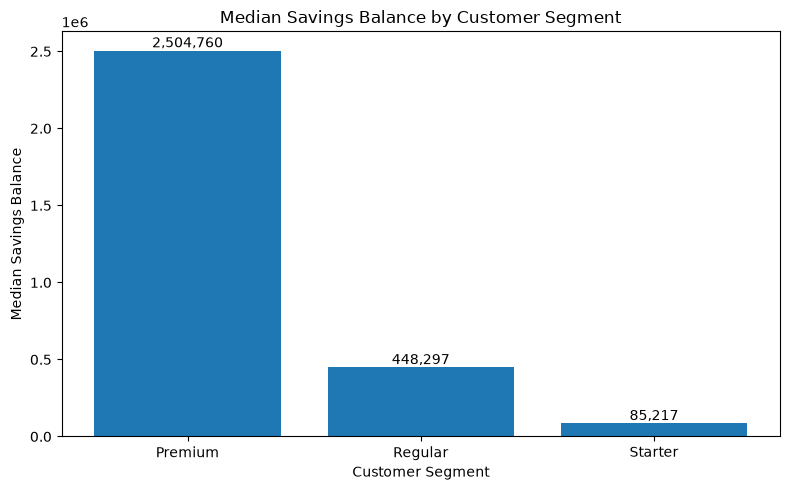

In [105]:
segment_summary = df.groupby("Customer_Segment")["Savings_Balance"].median()
segment_summary = segment_summary.sort_values(ascending=False)


plt.figure(figsize=(8, 5))
plt.bar(segment_summary.index, segment_summary.values)

plt.title("Median Savings Balance by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Median Savings Balance")


for i, value in enumerate(segment_summary.values):
    plt.text(i, value, f"{value:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

**What can the organization learn?**
Since the "Premium" customers have a significantly higher median savings compared with "Regular", it is recommended to push more products and investment opportunities towards them while keeping more affordable savings plans for "Regular" and "Starter" customers.

In [98]:
summarize("Province")

,count,mean,median
Province,,,
Eastern,49,965044.0,562848.0
North Western,54,772540.0,521604.0
Central,44,749496.0,457667.0
Western,99,862325.0,444781.0
Uva,50,630638.0,416564.0
Sabaragamuwa,54,925221.0,409667.0
Northern,57,627964.0,398536.0
Southern,82,654989.0,378636.0


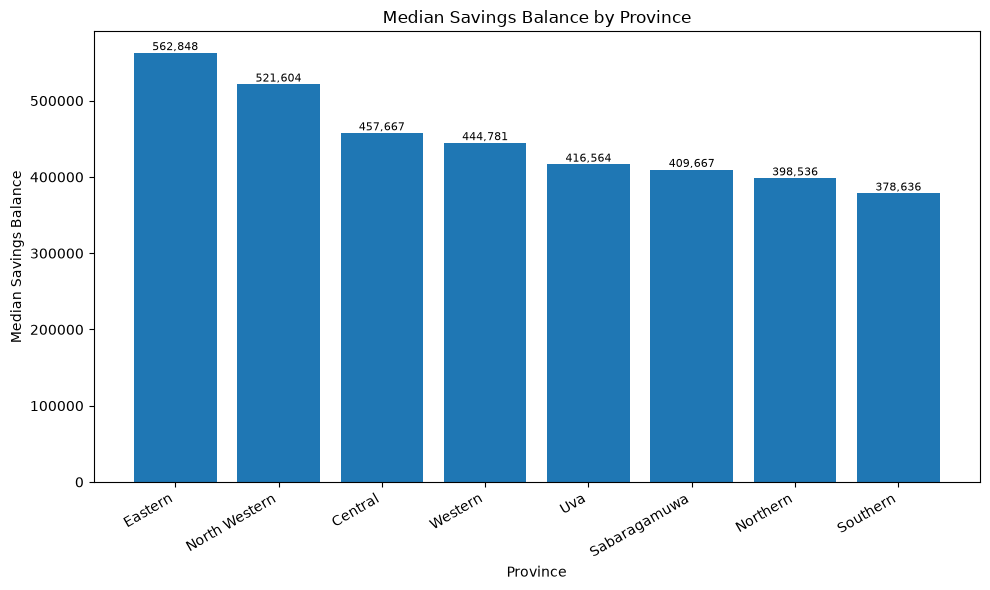

In [106]:
province_summary = df.groupby("Province")["Savings_Balance"].median()
province_summary = province_summary.sort_values(ascending=False)


plt.figure(figsize=(10, 6))
plt.bar(province_summary.index, province_summary.values)

plt.title("Median Savings Balance by Province")
plt.xlabel("Province")
plt.ylabel("Median Savings Balance")
plt.xticks(rotation=30, ha="right")


for i, value in enumerate(province_summary.values):
    plt.text(i, value, f"{value:,.0f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

**What can the organization learn?**
An organization can consider targeted campaigns based on the median savings per district. It would also help 'Business Intelligence' for them to investigate reasons for these differences.

In [99]:
summarize("Urban_Rural")

,count,mean,median
Urban_Rural,,,
Urban,184,898119.0,512587.0
Rural,120,733468.0,429710.0
Suburban,185,676103.0,368052.0


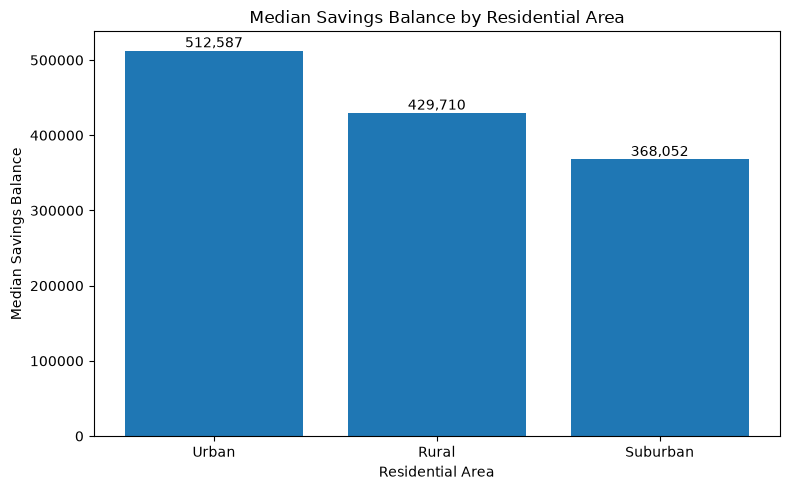

In [107]:
area_summary = df.groupby("Urban_Rural")["Savings_Balance"].median()
area_summary = area_summary.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(area_summary.index, area_summary.values)

plt.title("Median Savings Balance by Residential Area")
plt.xlabel("Residential Area")
plt.ylabel("Median Savings Balance")

for i, value in enumerate(area_summary.values):
    plt.text(i, value, f"{value:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

**What can the organization learn?**
Current results don't provide much else to go with but they can be used to trigger an investigation into why these differences occur and perhaps find insights there.

In [108]:
age = df.groupby("Age_Band", observed=True)["Savings_Balance"].agg(
    customers="count", total="sum", average="mean", typical="median")

age["share_of_all_savings_%"] = (
    age["total"] / age["total"].sum() * 100).round(1)
age.round(0)

,customers,total,average,typical,share_of_all_savings_%
Age_Band,,,,,
18-24,64,46986466.0,734164.0,310683.0,12.0
25-34,151,125625998.0,831960.0,479313.0,33.0
35-44,145,116468635.0,803232.0,455293.0,31.0
45+,128,88755358.0,693401.0,461261.0,24.0


In [110]:
growing = (df["Net_Monthly_Flow"] > 0).mean() * 100
draining = (df["Net_Monthly_Flow"] < 0).mean() * 100
print(f"Growing: {growing:.1f}%   Draining: {draining:.1f}%")
print("Smallest net flow in the data:", df["Net_Monthly_Flow"].min())

Growing: 100.0%   Draining: 0.0%
Smallest net flow in the data: 30.87


In [111]:
df["Flow_Pct_Of_Balance"] = df["Net_Monthly_Flow"] / df["Savings_Balance"]
print(df["Flow_Pct_Of_Balance"].describe())
active_growing = ((df["Net_Monthly_Flow"] > 0) &
                  (df["Monthly_Transaction_Count"] > 0)).mean() * 100
print(f"Growing AND actively transacting: {active_growing:.1f}%")
print(df["Account_Status"].value_counts(normalize=True).round(3) * 100)

count    489.000000
mean       0.020308
std        0.011896
min        0.002386
25%        0.010269
50%        0.018176
75%        0.027780
max        0.055313
Name: Flow_Pct_Of_Balance, dtype: float64
Growing AND actively transacting: 94.6%
Account_Status
Active       75.4
Inactive     16.0
Suspended     8.6
Name: proportion, dtype: float64
